# Lab 12: How to build the same RAG agent with LlamaIndex

## Goal

Rebuild the search agent of lab 11 with LlamaIndex, and see which hand-written piece each LlamaIndex object replaces:
the files become `Document`s and `Node`s, an index searches them, a query engine answers from them, and a
`FunctionAgent` runs the loop. The moment comes in Parts F and G, on a rep's question that needs two files the
question does not name. Given a **query engine** as its tool, the agent never reads a file: it reads a sentence that
a second model call wrote about the files, and that sentence drops ticket 06's pointer to the damaged-media policy.
The agent then found the damaged-media policy in only 3 of 10 runs and gave both facts in 2. Given a **retriever tool**, which returns the files' text and names as lab 11's search
did, the same agent found the policy and gave both facts in 10 of 10 runs, with fewer model calls.

## What you will learn

- How to turn the shop's files into LlamaIndex `Document`s with metadata, and print what the embedding model and the
  LLM each read from one.
- How a splitter turns `Document`s into `Node`s, and why our files stay one node each at the default chunk size.
- How to build the LLM and the embedding model from `models.env`, what LlamaIndex uses when you set nothing, and how
  to count every model call's tokens from the usage the API reports.
- How to index the nodes, retrieve with the default top k, check the search against the same arithmetic done by
  hand, and narrow it with a metadata filter.
- How a query engine writes an answer from the nodes it retrieved, which prompt it sends, and where its
  `source_nodes` are.
- How to give a `FunctionAgent` a query-engine tool or a retriever tool, what each one lets the agent read, and what
  each costs in model calls.

## Where this lab starts

Lab 11 built a search agent by hand: a `retrieve` function over the 36 files, a JSON tool schema, and a loop that
sends the model's queries to the search and the files back to the model until it answers. This lab builds the same
agent in LlamaIndex, a framework for connecting a model to your data. The notebook restates everything it uses, so it
runs on its own.

![The LlamaIndex path: files become Documents, a splitter makes Nodes, the index stores one vector per Node, a retriever returns the nearest Nodes; a query engine writes a sentence from them (lit), a retriever tool returns their text and file names, and either one can be the agent's tool](resources/lab12_documents_to_answer.png)

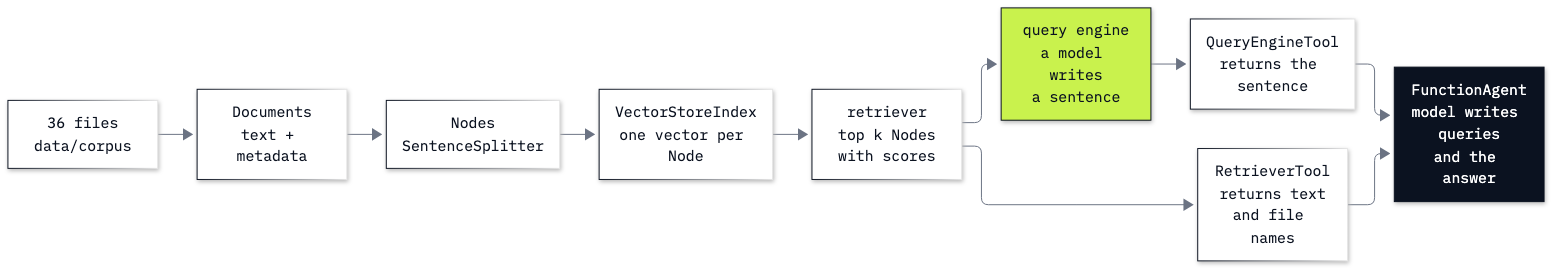

In [1]:
from IPython.display import Image

Image("resources/lab12_documents_to_answer.png", width=760)

Read the picture from the left. Everything up to the retriever is search: no model writes anything there, only the
embedding model turns text into vectors. The two branches on the right are the two ways to hand that search to an
agent. The lit box is the one to watch: a model call sits **between** the files and the agent, and the agent reads
what that call wrote, not the files.

---

## Setup

⚠️ **This lab runs on its own environment, not the repository's main one.** LlamaIndex's OpenAI integration needs
version 2 of the `openai` library, and the main environment has version 3, so the two cannot share one `.venv`. Create
it once with `uv sync --python 3.13` inside this folder (the README gives the `pip` route too), then choose
`12_LlamaIndex_RAG/.venv` as this notebook's kernel.

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the models and the
prices from there, and finds your key without printing it (Lab 00 reads it line by line).

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, a check that the kernel is the right one. `importlib.metadata.version` reads the version of an installed
package, without importing it.

In [3]:
from importlib.metadata import version

for package in ["llama-index-core", "llama-index-llms-openai", "llama-index-embeddings-openai", "openai"]:
    print(f"{package:30} {version(package)}")

llama-index-core               0.14.25
llama-index-llms-openai        0.8.3
llama-index-embeddings-openai  0.7.0
openai                         2.54.0


LlamaIndex comes as a small core (`llama-index-core`: documents, nodes, indexes, query engines, agents) plus one
package per integration; we installed only the two we use, the OpenAI LLM and the OpenAI embeddings. The last line
must start with **2**. If it says 3, the notebook is on the repository's main kernel: switch the kernel, or the
imports below fail.

---

## Part A: Represent the Files as Documents

LlamaIndex does not work on file paths or plain strings. Everything it indexes starts as a `Document`: the text plus
metadata about where it came from. We build one by hand from one file, look at what the models will read from it, and
then build all 36.

The shop's documents are 36 short markdown files in `data/corpus/`: 20 policies (the shop's rules) and 16 support
tickets (what happened to one customer). We read them in place and never change them. Here is the ticket our question
is about, exactly as it is on disk:

In [4]:
CORPUS = ROOT / "data" / "corpus"
path = CORPUS / "ticket_06_germany_warped_vinyl.md"
text = path.read_text(encoding="utf-8")
print(text)

# Ticket 06 — Germany, warped vinyl

Date: 2012-07-18
Customer: billing country Germany

Vinyl arrived warped. Customer sent a photo. Damaged-media policy: replace once at no charge.

Status: resolved. Replacement shipped 2012-07-20.



Ticket 06 is a record: a vinyl arrived warped, and the shop sent one free replacement. The rep's question, the same
one lab 11 asked, starts from it:

> *"Ticket 06's replacement arrived warped too. What do we offer now, and how long does the refund take?"*

A right answer needs two facts, and neither is in the ticket:

1. **What to offer now:** a refund instead of a third copy. It is in `policy_damaged_media.md`: *"If the same title
   arrives damaged twice, offer a refund instead of a third copy."*
2. **How long the refund takes:** 5 to 10 business days after support approves it. It is in `policy_refunds.md`.

Notice what the ticket does give: the line *"Damaged-media policy: replace once at no charge"* names the policy that
holds fact 1, without quoting its rule for a second time. A reader who follows that pointer finds the rule. Keep that
line in mind: in Part F it disappears.

Now the ticket as a `Document`. Its fields:

| Field | What we put in it | Why |
|---|---|---|
| `text` | the file's text, unchanged | what gets embedded and what the model reads |
| `id_` | the file name | a stable id, so every search result says which file it came from |
| `metadata` | `file_name`, and `kind` (`"ticket"` or `"policy"`, from the name) | facts about the text that are not the text |
| `excluded_embed_metadata_keys` | both keys | the embedding model sees the text only, as lab 10 embedded the files |
| `excluded_llm_metadata_keys` | `kind` | the LLM sees the file name, so it can say where a fact came from |

In [5]:
from llama_index.core import Document

ticket_06 = Document(
    text=text,
    id_=path.name,
    metadata={"file_name": path.name, "kind": "ticket"},
    excluded_embed_metadata_keys=["file_name", "kind"],
    excluded_llm_metadata_keys=["kind"],
)
print("id:      ", ticket_06.id_)
print("metadata:", ticket_06.metadata)

id:       ticket_06_germany_warped_vinyl.md
metadata: {'file_name': 'ticket_06_germany_warped_vinyl.md', 'kind': 'ticket'}


The metadata is stored with the text, but stored is not the same as shown to a model. `get_content` builds the text a
component will read, and its `metadata_mode` says for whom: `MetadataMode.EMBED` for the embedding model,
`MetadataMode.LLM` for the language model. Each mode leaves out the keys excluded for it.

In [6]:
from llama_index.core.schema import MetadataMode

print("--- what the embedding model reads ---")
print(ticket_06.get_content(metadata_mode=MetadataMode.EMBED))
print()
print("--- what the LLM reads ---")
print(ticket_06.get_content(metadata_mode=MetadataMode.LLM))

--- what the embedding model reads ---
# Ticket 06 — Germany, warped vinyl

Date: 2012-07-18
Customer: billing country Germany

Vinyl arrived warped. Customer sent a photo. Damaged-media policy: replace once at no charge.

Status: resolved. Replacement shipped 2012-07-20.


--- what the LLM reads ---
file_name: ticket_06_germany_warped_vinyl.md

# Ticket 06 — Germany, warped vinyl

Date: 2012-07-18
Customer: billing country Germany

Vinyl arrived warped. Customer sent a photo. Damaged-media policy: replace once at no charge.

Status: resolved. Replacement shipped 2012-07-20.


Two views of one object:

- **The embedding model** reads the ticket's text and nothing else, so its vector depends only on what the ticket
  says, not on its file name.
- **The LLM** reads one extra line at the top, `file_name: ticket_06_germany_warped_vinyl.md`. Whatever we hand the
  model later carries the file's name, so its answer can say which file a fact came from.
- `kind` is in neither view. It is there for our code: Part D filters the search with it.

**Important:** excluding a key controls what a model reads; it does not hide or protect the data. The metadata is
still in the object and in anything that saves it.

Now all 36 files, built the same way. `make_document` is the constructor above with the path as its only input;
`path.name.split("_")[0]` takes the part of the name before the first underscore, `policy` or `ticket`.

In [7]:
def make_document(path):
    return Document(
        text=path.read_text(encoding="utf-8"),
        id_=path.name,
        metadata={"file_name": path.name, "kind": path.name.split("_")[0]},
        excluded_embed_metadata_keys=["file_name", "kind"],
        excluded_llm_metadata_keys=["kind"],
    )


documents = [make_document(path) for path in sorted(CORPUS.glob("*.md"))]
kinds = [document.metadata["kind"] for document in documents]
print(len(documents), "documents:", kinds.count("policy"), "policies and", kinds.count("ticket"), "tickets")
print("first:", documents[0].id_, "| last:", documents[-1].id_)

36 documents: 20 policies and 16 tickets
first: policy_accounts.md | last: ticket_16_overpayment_note.md


36 `Document`s, one per file: 20 policies and 16 tickets, in the order of their names.

**In practice:** LlamaIndex's `SimpleDirectoryReader` reads a whole folder into `Document`s and fills in file metadata
for you (name, full path, size, dates), and other readers load PDFs, web pages or databases. We wrote the loop
ourselves to choose the metadata: a full path on your disk is not something we want every model call to read.

**Checkpoint A.** 36 documents (20 policies, 16 tickets); the embedding view of ticket 06 is its text alone, and the
LLM view starts with its `file_name` line.

---

## Part B: Split Documents into Nodes

The index does not search `Document`s; it searches `Node`s, the pieces a splitter cuts a document into. A long manual
would become many nodes, each small enough to embed and to fit in a prompt. This part shows what the default splitter
does to our files, and then to a document long enough to cut.

`SentenceSplitter` is LlamaIndex's default splitter. It cuts by token count but tries to end each piece at the end of
a sentence. A **token** is the unit a model reads, about three quarters of a word in English. Before running it,
predict: our files are a few short paragraphs each; how many nodes will 36 documents give at the default size?

In [8]:
from llama_index.core.node_parser import SentenceSplitter

splitter = SentenceSplitter()
print("chunk size:", splitter.chunk_size, "tokens | overlap:", splitter.chunk_overlap, "tokens")

nodes = splitter.get_nodes_from_documents(documents)
print(len(documents), "documents ->", len(nodes), "nodes")

chunk size: 1024 tokens | overlap: 200 tokens
36 documents -> 36 nodes


36 documents, 36 nodes: nothing was split. The default piece is 1,024 tokens, with 200 tokens shared between
neighbouring pieces (the overlap, so a sentence near a cut appears in both). A file shorter than one piece stays
whole. `get_tokenizer` is the tokenizer the splitter counts with; calling it on a text returns the list of its tokens,
so `len` of that list is the text's size in tokens.

In [9]:
from llama_index.core.utils import get_tokenizer

tokenizer = get_tokenizer()
sizes = {document.id_: len(tokenizer(document.text)) for document in documents}
longest = max(sizes, key=sizes.get)
print("longest file:", longest, "with", sizes[longest], "tokens")
print("all 36 files:", sum(sizes.values()), "tokens")

longest file: ticket_16_overpayment_note.md with 99 tokens
all 36 files: 2551 tokens


The longest file is 99 tokens, about a tenth of one piece, so every file fits in one node. `max(sizes,
key=sizes.get)` returns the dictionary key (a file name) whose value (its token count) is largest.

A node is more than a copy of the text. Here is ticket 06's node. `next(...)` takes the first item a generator
gives, here the first node whose source document is ticket 06.

In [10]:
node = next(n for n in nodes if n.ref_doc_id == "ticket_06_germany_warped_vinyl.md")
print("node id:      ", node.node_id)
print("from document:", node.ref_doc_id)
print("metadata:     ", node.metadata)
print("relationships:", {kind.name: info.node_id for kind, info in node.relationships.items()})
print("characters:", node.start_char_idx, "to", node.end_char_idx, "of", len(ticket_06.text))
print("same text as the document, final newline aside:", node.text == ticket_06.text.strip())

node id:       6b44ec8e-a0df-4dec-bfcc-c8553f390039
from document: ticket_06_germany_warped_vinyl.md
metadata:      {'file_name': 'ticket_06_germany_warped_vinyl.md', 'kind': 'ticket'}
relationships: {'SOURCE': 'ticket_06_germany_warped_vinyl.md'}
characters: 0 to 233 of 234
same text as the document, final newline aside: True


Reading the node field by field:

- **`node_id`** is a new random id; the node is a new object, not the document.
- **`ref_doc_id`** and the `SOURCE` relationship both point back to the document it came from, by the file name we
  gave as `id_`. This is how any search result can say which file it came from.
- **`metadata`** was copied from the document, with the same exclusions, so the node shows each model the same views.
- **`start_char_idx`** and **`end_char_idx`** say where in the document the node's text starts and ends. Here it is
  all of it except the final newline, which the splitter trims: the whole ticket, because nothing was cut.

To see a real split, we need a longer document. We join the 20 policies into one handbook, in memory (nothing is
written to `data/`), and split it twice: at the default size, and at 128 tokens, a size chosen only to make the cuts
easy to see.

In [11]:
policies = [document for document in documents if document.metadata["kind"] == "policy"]
handbook = Document(text="\n\n".join(document.text for document in policies), id_="handbook")
print("handbook:", len(tokenizer(handbook.text)), "tokens")

default_pieces = splitter.get_nodes_from_documents([handbook])
small_pieces = SentenceSplitter(chunk_size=128, chunk_overlap=20).get_nodes_from_documents([handbook])
print("chunk_size 1024:", len(default_pieces), "nodes")
print("chunk_size  128:", len(small_pieces), "nodes")

handbook: 1418 tokens
chunk_size 1024: 2 nodes
chunk_size  128: 16 nodes


The handbook is 1,418 tokens, so at the default size it becomes 2 nodes, and at 128
tokens 16. Here is how the second small piece begins and how it is linked:

In [12]:
piece = small_pieces[1]
print(piece.text[:300])
print("...")
print("source:", piece.ref_doc_id, "| links:", [kind.name for kind in piece.relationships])

# Cancellations

A physical order can be cancelled until it ships. After it ships, use the return policy.

A digital order can be cancelled only before the download starts. After the first byte, it is a completed digital sale.

To cancel, write to support with the invoice number the same day if you 
...
source: handbook | links: ['SOURCE', 'PREVIOUS', 'NEXT']


It begins at the heading *# Cancellations*, the start of the second policy: the splitter closed the first piece at the end of a sentence (the end of the accounts policy) instead of cutting one in half. Besides `SOURCE` (the handbook), a piece cut from a longer document has `PREVIOUS` and `NEXT` links to
its neighbours, so code can fetch the text around a hit.

**Our choice for the rest of the lab: one node per file.** Each file holds one topic and fits in one piece, and lab
10 and lab 11 searched whole files too, so every comparison in this lab is between the same units. Smaller pieces pay
off when documents are long and mix topics; lab 10 measures what a bad cut breaks.

**Checkpoint B.** 36 nodes from 36 files (the longest file 99 tokens); the handbook in 2
nodes at the default size and 16 at 128 tokens, with `PREVIOUS` and `NEXT` links.

---

## Part C: Build the Models from the Settings

LlamaIndex calls models in two places: an **embedding model** turns every node and every query into a vector, and an
**LLM** writes text, in the query engine and in the agent. Both come from `Settings`, a set of global defaults that
every index, query engine and agent reads when you do not pass a model yourself. First, what it holds when we set
nothing:

In [13]:
from llama_index.core import Settings

print("LLM:      ", type(Settings.llm).__name__, Settings.llm.model)
print("embedding:", type(Settings.embed_model).__name__, Settings.embed_model.model_name)
print("models.env:", MODEL, "and", settings["EMBEDDING_MODEL"])

LLM:       OpenAI gpt-3.5-turbo
embedding: OpenAIEmbedding text-embedding-ada-002
models.env: gpt-6-luna and text-embedding-3-small


Left alone, LlamaIndex falls back to its own defaults: OpenAI models, but not the ones `models.env` names. Code that
forgets to set `Settings` runs without any error, on models (and prices) you did not choose. So we build both models
from `models.env`, use each once directly, and only then make them the defaults.

**The LLM.** `OpenAI` from `llama_index.llms.openai` is LlamaIndex's wrapper around OpenAI's Chat Completions API
(the same API lab 11 called by hand, so the comparisons later are fair; the integration also has `OpenAIResponses` for
the newer Responses API). It shares its name with the `OpenAI` client of the `openai` library, but it is a different
class. We pass three settings:

- `model=MODEL` from `models.env`;
- `reasoning_effort=EFFORT` (`none` here; when `models.env` leaves it empty, `EFFORT` is `None` and the wrapper sends
  no effort at all);
- `max_tokens=300` to cap each reply.

To see what the wrapper turns these into, we print the arguments it will send with every request. `_get_model_kwargs`
is a private method (the leading underscore says so); we call it only to look.

In [14]:
from llama_index.llms.openai import OpenAI

MAX_OUTPUT = 300
llm = OpenAI(model=MODEL, reasoning_effort=EFFORT, max_tokens=MAX_OUTPUT)
print(llm._get_model_kwargs())

{'model': 'gpt-6-luna', 'temperature': 1.0, 'max_completion_tokens': 300, 'reasoning_effort': 'none'}


The wrapper knows this model family: it sends our cap as `max_completion_tokens` (the name these models accept; they
refuse `max_tokens`), sets `temperature` to 1 for this model family (with reasoning on, they accept no other value), and passes the
effort through.
Now one call on a small message. `chat` takes a list of `ChatMessage`s, the same role-and-content messages lab 11
built as dictionaries.

In [15]:
from llama_index.core.llms import ChatMessage

reply = llm.chat([ChatMessage(role="user", content="In one sentence, what does a music shop's support rep do?")])
print(type(reply).__name__)
print(reply.message.content)
print(reply.raw.usage)

ChatResponse
A music shop’s support rep helps customers with product questions, orders, returns, and other service issues.
CompletionUsage(completion_tokens=24, prompt_tokens=20, total_tokens=44, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=0, rejected_prediction_tokens=0), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=0))


`chat` returns a `ChatResponse`:

- `reply.message` is the model's message, with its `role` and `content`;
- `reply.raw` is the API's own response object, unchanged, and `reply.raw.usage` is what the API billed:
  `prompt_tokens` sent, `completion_tokens` received (here 20 sent and 24 received).

**The embedding model.** `OpenAIEmbedding` wraps OpenAI's embeddings endpoint. `get_text_embedding` embeds a text
the way an index embeds a node. We give it ticket 06's embedding view, the text Part A printed.

In [16]:
from llama_index.embeddings.openai import OpenAIEmbedding

embed_model = OpenAIEmbedding(model=settings["EMBEDDING_MODEL"])
vector = embed_model.get_text_embedding(ticket_06.get_content(metadata_mode=MetadataMode.EMBED))
print(type(vector).__name__, "of", len(vector), "numbers | first three:", [round(x, 4) for x in vector[:3]])
print("length:", round(sum(x * x for x in vector) ** 0.5, 4))

list of 1536 numbers | first three: [-0.0446, 0.0434, -0.0406]
length: 1.0001


A plain Python `list` of 1,536 numbers, with length 1.0001, which is 1 within rounding: the same kind of vector lab 10 got from the
embeddings endpoint directly. The wrapper adds nothing to the vector; it saves us the request code and batches many
texts into one request when an index embeds them.

Both work, so we make them the defaults. From here on, every LlamaIndex object that needs a model uses these two.

In [17]:
Settings.llm = llm
Settings.embed_model = embed_model
print("LLM:", Settings.llm.model, "| embedding:", Settings.embed_model.model_name)

LLM: gpt-6-luna | embedding: text-embedding-3-small


### Count every model call from the usage the API reports

In this lab, model calls happen inside LlamaIndex objects: a query engine makes one, an agent several, and a tool can
make its own. To compare costs we need every call's usage, wherever it happens, without changing those objects.

LlamaIndex has two systems for this. The older one, `CallbackManager` with `TokenCountingHandler`, counts tokens
itself with a local tokenizer, an estimate. The current one is the **instrumentation** module: every LLM call sends
events to a dispatcher, and a handler we register receives them. The event `LLMChatEndEvent` carries the messages
that were sent and the `ChatResponse` that came back, with the same `raw.usage` we just read. So our handler reads the
API's own numbers.

`UsageLog.handle` runs once for every event; it keeps only the end of each chat call, and appends what was sent and
the two token counts to `CALLS`. ⚠️ Run this cell once: running it again registers a second handler, and every call
is then counted twice (restart the kernel to undo it).

In [18]:
from llama_index.core.instrumentation import get_dispatcher
from llama_index.core.instrumentation.event_handlers import BaseEventHandler
from llama_index.core.instrumentation.events.llm import LLMChatEndEvent

CALLS = []  # one entry per model call: the messages sent and the tokens the API reported


class UsageLog(BaseEventHandler):
    def handle(self, event, **kwargs):
        if isinstance(event, LLMChatEndEvent):
            usage = event.response.raw.usage
            CALLS.append({"messages": event.messages, "input": usage.prompt_tokens, "output": usage.completion_tokens})


get_dispatcher().add_event_handler(UsageLog())

To check it, the same call again, then what the log holds. `cost` prices a list of calls from `models.env` (US
dollars per million tokens).

In [19]:
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])


def cost(calls):
    return sum(call["input"] * PRICE_IN + call["output"] * PRICE_OUT for call in calls) / 1_000_000


llm.chat([ChatMessage(role="user", content="In one sentence, what does a music shop's support rep do?")])
print(len(CALLS), "call logged:", CALLS[-1]["input"], "input tokens,", CALLS[-1]["output"], "output tokens,",
      f"${cost(CALLS):.7f}")

1 call logged: 20 input tokens, 22 output tokens, $0.0000130


One call logged, with 20 input and 22 output tokens ($0.0000130): the handler recorded it with no change to the call itself. The
embedding calls are not in `CALLS` (they are another kind of event); at the embedding price in `models.env`, all of
this lab's embeddings together cost a small fraction of one cent.

**Checkpoint C.** The defaults print models that are not the ones in `models.env`; ours print after `Settings` is
set; one logged call with its input and output tokens.

---

## Part D: Index and Retrieve

A search needs every node embedded and stored. `VectorStoreIndex` does both in one line: it embeds the 36 nodes with
`Settings.embed_model` (in one batched request) and keeps the vectors in a vector store, by default
`SimpleVectorStore`, which lives in memory in this kernel.

In [20]:
from llama_index.core import VectorStoreIndex

index = VectorStoreIndex(nodes)
store = index.vector_store
print(type(store).__name__, "holds", len(store.data.embedding_dict), "vectors")

SimpleVectorStore holds 36 vectors


36 vectors, one per node, kept in a dictionary from node id to vector. Nothing is written to disk; rerunning the
notebook embeds the files again.

A **retriever** embeds a query and returns the nearest nodes. `index.as_retriever()` makes one with the default
`similarity_top_k`, the number of nodes it returns. Here it is on our question:

In [21]:
from llama_index.core.constants import DEFAULT_SIMILARITY_TOP_K

QUESTION = "Ticket 06's replacement arrived warped too. What do we offer now, and how long does the refund take?"

retriever = index.as_retriever()
found = retriever.retrieve(QUESTION)
print("default top k:", DEFAULT_SIMILARITY_TOP_K)
for item in found:
    print(f"{item.score:.4f}  {item.node.metadata['file_name']}")

default top k: 2
0.6122  ticket_06_germany_warped_vinyl.md
0.4842  policy_refunds.md


The retriever returns a list of `NodeWithScore`: each item holds a `node` (the whole node, metadata included) and a
`score`. The default top k is **2**, a number worth knowing, because every object built from this index without
saying otherwise (the query engine in Part E among them) sees only 2 nodes.

The score is the **cosine similarity** of the query's vector and the node's: higher means closer. (Lab 10's Chroma
reported a distance, where lower means closer; for vectors of length 1 the two give the same order.) Ticket 06 comes first (0.6122): the question names it. `policy_refunds.md` is second (0.4842), and it holds fact 2. The damaged-media policy, which holds fact 1, is not in the top 2.

Is this search anything more than the arithmetic lab 10 did by hand? We can check. `store.get(node_id)` returns a
node's stored vector; we stack the 36 into a matrix, embed the question with `get_query_embedding`, and compute the
36 cosines in one matrix product:

- `node_vectors` has shape (36, 1536): one row per node, in the order of `nodes`;
- `node_vectors @ query_vector` gives 36 dot products, one per row;
- dividing by the lengths (`np.linalg.norm`, `axis=1` meaning one length per row) turns them into cosines;
- `np.argsort(-scores)` lists the row numbers from the highest score down.

In [22]:
import numpy as np

names = [n.metadata["file_name"] for n in nodes]
node_vectors = np.array([store.get(n.node_id) for n in nodes])
query_vector = np.array(embed_model.get_query_embedding(QUESTION))

scores = node_vectors @ query_vector / (np.linalg.norm(node_vectors, axis=1) * np.linalg.norm(query_vector))
print("matrix:", node_vectors.shape)
for i in np.argsort(-scores)[:6]:
    print(f"{scores[i]:.4f}  {names[i]}")

matrix: (36, 1536)
0.6122  ticket_06_germany_warped_vinyl.md
0.4842  policy_refunds.md
0.4824  ticket_07_uk_preorder_delay.md
0.4647  ticket_01_helena_wrong_album.md
0.4423  policy_damaged_media.md
0.4295  ticket_11_ireland_exchange.md


The first two rows are the retriever's two nodes, with the same scores to four decimals (0.6122 and 0.4842). **The retriever is the cosine
search, run for us.** Further down, the list shows what a 2-node search leaves out: `policy_damaged_media.md`, the file that holds fact 1, is 5th at 0.4423, behind two tickets about other customers (07 and 01).

One question can agree by chance, so we check the two searches on more: eight questions of the kind lab 10 labelled,
each with the one file that answers it, written down before searching. For each, the retriever's top 3 and the hand
search's top 3, and where the right file ranks. `search_by_hand` is the cell above as a function.

In [23]:
def search_by_hand(query, k):
    q = np.array(embed_model.get_query_embedding(query))
    s = node_vectors @ q / (np.linalg.norm(node_vectors, axis=1) * np.linalg.norm(q))
    return [names[i] for i in np.argsort(-s)[:k]]


LABELLED = [
    ("How long do I have to return an unopened CD?", "policy_returns.md"),
    ("When is support staffed?", "policy_support_hours.md"),
    ("Do gift cards expire?", "policy_gift_cards.md"),
    ("How many business days does a refund take?", "policy_refunds.md"),
    ("My download link expired. Can I get a new one?", "policy_digital_downloads.md"),
    ("Can I pay with bitcoin?", "policy_payment.md"),
    ("Is there a phone number I can call for support?", "policy_data_retention.md"),
    ("Can you ship the second disc of my set separately?", "policy_shipping.md"),
]

top_3 = index.as_retriever(similarity_top_k=3)
hits_1 = hits_3 = same = 0
for question, label in LABELLED:
    by_library = [item.node.metadata["file_name"] for item in top_3.retrieve(question)]
    by_hand = search_by_hand(question, 3)
    rank = by_library.index(label) + 1 if label in by_library else None
    hits_1 += rank == 1
    hits_3 += rank is not None
    same += by_library == by_hand
    print(f"{question:52} rank {str(rank or '-'):2} | same top 3 by hand: {by_library == by_hand}")
print(f"hit@1 {hits_1} of 8 | hit@3 {hits_3} of 8 | same top 3 as by hand: {same} of 8")

How long do I have to return an unopened CD?         rank 1  | same top 3 by hand: True


When is support staffed?                             rank 2  | same top 3 by hand: True


Do gift cards expire?                                rank 1  | same top 3 by hand: True


How many business days does a refund take?           rank 1  | same top 3 by hand: True


My download link expired. Can I get a new one?       rank 2  | same top 3 by hand: True


Can I pay with bitcoin?                              rank 1  | same top 3 by hand: True


Is there a phone number I can call for support?      rank -  | same top 3 by hand: True


Can you ship the second disc of my set separately?   rank -  | same top 3 by hand: True
hit@1 4 of 8 | hit@3 6 of 8 | same top 3 as by hand: 8 of 8


Two measures, each a count over the eight questions:

- **hit@1:** the right file came first (4 of 8);
- **hit@3:** the right file was somewhere in the top 3 (6 of 8).

Two answers come second: support hours (the support reps' file ranks above the hours file) and the expired download link (Puja's ticket about the same problem ranks above the policy). Two never reach the top 3, and both are answers hidden in a file named for something else: "support is email only" sits in `policy_data_retention.md`, and "we do not split a single invoice across two parcels" in `policy_shipping.md`. The last column is the check this table is for: the retriever and the hand search returned the same
three files in the same order for 8 of 8 questions. A pass shows that LlamaIndex's search adds no ranking
of its own on top of cosine similarity; it does not show that the search is good, which the hit counts measure.

### Narrow the search with a metadata filter

The `kind` field from Part A was kept away from both models so our code could use it. A metadata filter restricts a
search to nodes whose metadata matches, before any ranking: `MetadataFilters` holds a list of `MetadataFilter`s, each
a key and a value (equality by default).

In [24]:
from llama_index.core.vector_stores import MetadataFilter, MetadataFilters

policies_only = MetadataFilters(filters=[MetadataFilter(key="kind", value="policy")])
for item in index.as_retriever(filters=policies_only).retrieve(QUESTION):
    print(f"{item.score:.4f}  {item.node.metadata['file_name']}")

0.4842  policy_refunds.md
0.4423  policy_damaged_media.md


With the filter, the two nodes are `policy_refunds.md` (0.4842) and `policy_damaged_media.md` (0.4423): exactly the two files that hold the two facts, because the tickets that outranked the damaged-media policy are gone. The scores did not change; the filter only removed the tickets from the race.

That is a real option when **our code** knows where an answer lives: a question about the shop's rules can search the
policies only. It is our decision, written in code, not the model's. Part E puts this filter to work; the agent in
Parts F and G gets no filter and has to find the files itself.

**Checkpoint D.** 36 vectors in a `SimpleVectorStore`; default top k 2, with ticket 06 and `policy_refunds.md` for our question; the
same top 3 as the hand search for 8 of 8 questions (hit@1 4, hit@3 6); with the
policy filter, `policy_refunds.md` and `policy_damaged_media.md`.

---

## Part E: Ask a Query Engine

A retriever returns nodes, not an answer. To answer, we would pack the nodes into a prompt and call the model, which
is lab 10's generate step. A **query engine** does exactly that: it retrieves (top 2 by default), puts the nodes'
LLM views into a prompt template, makes one model call, and returns a `Response` that keeps the nodes it used. It is
the most common way LlamaIndex is used, and the shortest.

In [25]:
query_engine = index.as_query_engine()

start = len(CALLS)
response = query_engine.query(QUESTION)
print(type(response).__name__)
print(response.response)
print("model calls:", len(CALLS) - start)

Response
Because the replacement was also warped, offer a refund. Once approved, it goes back to the original payment method and takes 5 to 10 business days.
model calls: 1


One model call, and a fluent answer that offers a refund and gives 5 to 10 business days. It reads as right. Before we trust it, we check it and look at where it came from.

To score answers the same way all through the lab, we write down in code what a right answer contains, as lab 11 did:
`check_facts` looks for fact 1 (a refund, with "instead", "rather than", "third" or "twice" saying it replaces a
further copy) and fact 2 ("5 to 10 business days", with "to" or a dash). It is a keyword check, so we read every reply
it scores, not only its marks.

In [26]:
import re


def check_facts(text):
    text = (text or "").lower()
    rule = "refund" in text and any(phrase in text for phrase in ["third", "instead", "rather than", "twice"])
    days = re.search(r"5\s*(to|-|–)\s*10 business days", text) is not None
    return {"refund instead of a third copy": rule, "5 to 10 business days": days}


def marks(facts):
    return " ".join(("✅" if ok else "❌") + " " + name for name, ok in facts.items())


print(marks(check_facts(response.response)))
for item in response.source_nodes:
    print(f"source: {item.score:.4f}  {item.node.metadata['file_name']}")

❌ refund instead of a third copy ✅ 5 to 10 business days
source: 0.6122  ticket_06_germany_warped_vinyl.md
source: 0.4842  policy_refunds.md


Fact 2 passes. Fact 1 fails: the answer offers a refund but never says it replaces a further copy, and the sources show why. The engine read ticket 06 and `policy_refunds.md`, not the damaged-media policy, so the model **inferred** the refund from the ticket's *replace once* and the refunds file. Here the guess matches the rule; had the rule said *store credit*, the same reasoning would have been wrong, and the answer would have read just as well. `response.source_nodes` is the same list of `NodeWithScore` the retriever returned: the evidence
the answer was written from. **Always read the sources beside the answer:** here they say the damaged-media policy was
never in front of the model.

What exactly did the model read? Our usage log kept the messages of every call; the last one is the query engine's.
`message.role.value` is the role as plain text.

In [27]:
for message in CALLS[-1]["messages"]:
    print(f"--- {message.role.value} ---")
    print(message.content)

--- system ---
You are an expert Q&A system that is trusted around the world.
Always answer the query using the provided context information, and not prior knowledge.
Some rules to follow:
1. Never directly reference the given context in your answer.
2. Avoid statements like 'Based on the context, ...' or 'The context information ...' or anything along those lines.
--- user ---
Context information is below.
---------------------
file_name: ticket_06_germany_warped_vinyl.md

# Ticket 06 — Germany, warped vinyl

Date: 2012-07-18
Customer: billing country Germany

Vinyl arrived warped. Customer sent a photo. Damaged-media policy: replace once at no charge.

Status: resolved. Replacement shipped 2012-07-20.

file_name: policy_refunds.md

# Refunds

Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.

Partial refunds are allowed when only some tracks on a multi-disc set are defective.

We do not refund because a customer change

This is the prompt a query engine writes. Reading it from the top:

- a **system** message from LlamaIndex's default template, telling the model to answer from the context, not from
  prior knowledge, and never to mention the context. That second rule is why the answer names no file, though both
  file names are in front of the model;
- a **user** message with the two nodes in their LLM view (the `file_name` line, then the text) between dashed
  lines, then our question.

Nothing in it is hidden or clever: it is lab 10's pack-and-generate step with LlamaIndex's wording. The weak point is
the search in front of it: 2 nodes, and the rule for a second damaged copy is not among them.

Part D's filter offers a cheap fix for this question: a query engine that searches the policies only.

In [28]:
policy_engine = index.as_query_engine(filters=policies_only)

start = len(CALLS)
policy_response = policy_engine.query(QUESTION)
policy_calls = CALLS[start:]
print(policy_response.response)
print(marks(check_facts(policy_response.response)))
print("sources:", [item.node.metadata["file_name"] for item in policy_response.source_nodes])
print("model calls:", len(policy_calls), "| tokens in:", policy_calls[0]["input"], "| out:", policy_calls[0]["output"])

Offer a refund instead of another replacement. After support approves it, the refund takes 5–10 business days to reach the original payment method.
✅ refund instead of a third copy ✅ 5 to 10 business days
sources: ['policy_refunds.md', 'policy_damaged_media.md']
model calls: 1 | tokens in: 298 | out: 32


Both facts, from both policy files, in one call of 298 input and 32 output tokens. **When our code knows where the answer lives, a filtered query engine answers in one call, and no
agent is needed.** It is not a general fix: the filter is our guess about the question, and it removes the tickets,
so a question about what a ticket says would now fail. A rep's questions do not come labelled; the next step is to let
the model choose its own searches.

**Checkpoint E.** The default engine: one call, sources ticket 06 and `policy_refunds.md`, fact 2 only (a refund offered, but not from the rule). The policy-only engine:
one call, sources `policy_refunds.md` and `policy_damaged_media.md`, both facts.

---

## Part F: Give an Agent the Query Engine as a Tool

Lab 11's agent wrote its own queries: it read ticket 06, saw the damaged-media policy named there, and searched for it.
In LlamaIndex the quickest way to give an agent search is to wrap the query engine we already have as a tool.
`QueryEngineTool.from_defaults` takes the engine, a name and a description, and LlamaIndex writes the tool schema the
model sees. The description is lab 11's wording; its examples are about other topics on purpose, so they cannot hand
the model a query for our question.

In [29]:
import json

from llama_index.core.tools import QueryEngineTool

DESCRIPTION = (
    "Search the shop policy and customer ticket files. "
    "Argument input must be a concise keyword phrase (e.g. 'gift card expiry', 'student discount', 'Puja ticket')."
)
qe_tool = QueryEngineTool.from_defaults(query_engine=query_engine, name="search", description=DESCRIPTION)
print(json.dumps(qe_tool.metadata.to_openai_tool(), indent=2))

{
  "type": "function",
  "function": {
    "name": "search",
    "description": "Search the shop policy and customer ticket files. Argument input must be a concise keyword phrase (e.g. 'gift card expiry', 'student discount', 'Puja ticket').",
    "parameters": {
      "properties": {
        "input": {
          "title": "Input",
          "type": "string"
        }
      },
      "required": [
        "input"
      ],
      "type": "object"
    }
  }
}


`to_openai_tool()` prints the schema in Chat Completions' tool format, the same shape lab 11 wrote by hand: a name,
our description, and one required string argument, here called `input`. LlamaIndex wrote it from the tool, so we
never touch the JSON.

Now the agent. `FunctionAgent` is LlamaIndex's agent for models with native tool calls; it runs the loop lab 11
wrote: call the model with the tools, run every tool it asks for, append the results, and call again until it
answers. We give it:

- `tools=[qe_tool]`, the only tool it can call;
- `llm=llm`, our model (it would also take `Settings.llm`);
- `system_prompt`: a short, plain instruction, the kind a first version starts with;
- `streaming=False`, so each model call returns whole, with its usage (a streamed reply arrives in pieces and, by
  default, without usage).

In [30]:
from llama_index.core.agent.workflow import FunctionAgent

PROMPT = "You answer questions about the shop's policies and support tickets. Use the search tool to find the facts."

qe_agent = FunctionAgent(tools=[qe_tool], llm=llm, system_prompt=PROMPT, streaming=False)
print(type(qe_agent).__name__, "| name:", qe_agent.name, "| tools:", [tool.metadata.name for tool in qe_agent.tools])

FunctionAgent | name: Agent | tools: ['search']


One run, with the loop made visible. Three things in this cell are new:

1. `qe_agent.run(user_msg=..., max_iterations=10)` starts the agent and returns a **handler** at once, before any
   model call. `max_iterations` is the turn cap lab 11 wrote (LlamaIndex's default is 20).
2. `async for event in handler.stream_events()` receives the agent's events as they happen. A `ToolCallResult`
   event comes after every tool call, with the arguments the model wrote (`tool_kwargs`) and what the tool returned
   (`tool_output.content`, the text the agent reads). Other events (`ToolCall`, `AgentOutput`) mark the call itself and
   each model reply; we print only the results.
3. `await handler` waits for the end and gives the final `AgentOutput`; `result.response.content` is the answer.

Jupyter lets a cell use `async for` and `await` at the top level, without writing an `async def` around them.

In [31]:
from llama_index.core.agent.workflow import ToolCallResult

start = len(CALLS)
handler = qe_agent.run(user_msg=QUESTION, max_iterations=10)
async for event in handler.stream_events():
    if isinstance(event, ToolCallResult):
        print("query: ", event.tool_kwargs["input"])
        print("result:", event.tool_output.content)
        print()
result = await handler
print("answer:", result.response.content)
print(marks(check_facts(result.response.content)), "| model calls:", len(CALLS) - start)

query:  Ticket 06 replacement arrived warped refund offer processing time
result: Ticket 06 records a replacement shipped on 2012-07-20. It doesn’t say whether the replacement arrived warped or mention a refund offer or processing time.



query:  Ticket 06 warped replacement refund
result: The warped vinyl qualified for one replacement at no charge. It was shipped on 2012-07-20; no refund is noted.



query:  refund processing time shop policy
result: Refunds take 5–10 business days after support approves the request and are returned to the original payment method.



query:  replacement defective warped second replacement refund store credit ticket policy
result: If the same title arrives damaged a second time, offer a refund instead of sending a third copy. The policy does not specify store credit.



answer: Because the replacement is warped too, we can offer a refund rather than send a third copy. Once support approves it, the refund goes to your original payment method and takes **5–10 business days**.
✅ refund instead of a third copy ✅ 5 to 10 business days | model calls: 9


Read the results, not only the answer. This run searched four times: ticket 06 twice, then refund times, and only its fourth query, about a *second replacement*, brought back the rule: *"If the same title arrives damaged a second time, offer a refund instead of sending a third copy."* The answer has both facts, after 9 model calls: 5 by the agent (one per turn) and one inside the tool for each of the 4 searches.

Every `result:` line is a sentence the query engine's model wrote, not a file. The agent sees no file name and no
policy text. Compare the ticket on disk, *"Damaged-media policy: replace once at no charge"*, with what the engine
said about it: *"The warped vinyl qualified for one replacement at no charge. It was shipped on 2012-07-20; no refund is noted."* The pointer to the damaged-media policy, the one clue that tells a reader where
to look next, is gone: the sentence keeps *one replacement at no charge* and drops the words *Damaged-media policy*. This run found the rule anyway, on its fourth search. The ten runs below show how often that happens.

Count the model calls too: each search is a full query engine run, so every search costs a model call **inside** the
tool, on top of the agent's own calls.

One run proves little; the model's queries change from run to run. We run the agent ten times. `run_agent` is the
cell above as a function: it returns the answer, every search (the query, the files the search found, the text the
agent read), and the calls and tokens from the log. The files come from `tool_output.raw_output`, the tool's raw
result: for a query engine a `Response`, whose `source_nodes` we read; for the retriever tool in Part G a plain list of
nodes. `hasattr(raw, "source_nodes")` tells the two apart.

In [32]:
RULE_FILE = "policy_damaged_media.md"  # the file that holds fact 1


async def run_agent(agent, question):
    start = len(CALLS)
    handler = agent.run(user_msg=question, max_iterations=10)
    searches = []
    async for event in handler.stream_events():
        if isinstance(event, ToolCallResult):
            raw = event.tool_output.raw_output
            found = raw.source_nodes if hasattr(raw, "source_nodes") else raw
            searches.append({
                "query": event.tool_kwargs["input"],
                "files": [item.node.metadata["file_name"] for item in found],
                "read": event.tool_output.content,
            })
    result = await handler
    calls = CALLS[start:]
    answer = result.response.content
    return {
        "answer": answer,
        "searches": searches,
        "facts": check_facts(answer),
        "rule_found": any(RULE_FILE in search["files"] for search in searches),
        "calls": len(calls),
        "input": sum(call["input"] for call in calls),
        "output": sum(call["output"] for call in calls),
        "cost": cost(calls),
    }


async def run_many(agent, n):
    runs = []
    for i in range(1, n + 1):
        run = await run_agent(agent, QUESTION)
        runs.append(run)
        print(f"run {i:2}: {marks(run['facts'])} | rule file found: {run['rule_found']!s:5} | "
              f"{len(run['searches'])} searches, {run['calls']} model calls")
    return runs

Each line will show the two fact checks and a third check, **rule file found**: whether any search returned
`policy_damaged_media.md`, read from the tool's raw result, not from the answer. It tells us whether the rule could
have reached the agent at all. Predict before you run: with a sentence instead of the files, how often will the agent
find its way to the damaged-media rule?

In [33]:
qe_runs = await run_many(qe_agent, 10)

run  1: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 2 searches, 5 model calls


run  2: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 3 searches, 7 model calls


run  3: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 2 searches, 5 model calls


run  4: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 7 model calls


run  5: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 3 searches, 7 model calls


run  6: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 3 searches, 7 model calls


run  7: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 3 searches, 7 model calls


run  8: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: False | 3 searches, 7 model calls


run  9: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 2 searches, 5 model calls


run 10: ✅ refund instead of a third copy ❌ 5 to 10 business days | rule file found: True  | 2 searches, 5 model calls


Both facts in 2 of 10 runs, and the rule file found in only 3 of 10: in seven runs no search ever returned `policy_damaged_media.md`. Fact 2 came through in 9 of 10, because refund times are easy to search for by name. Every run cost 5 or 7 model calls. `print_failures` prints every run that missed a fact: the queries the agent wrote, the files each
search found, what the tool said back, and the answer. Part H uses it again.

In [34]:
def print_failures(runs):
    for i, run in enumerate(runs, 1):
        if not all(run["facts"].values()):
            print(f"--- run {i}: {marks(run['facts'])}")
            for search in run["searches"]:
                print("  query: ", search["query"], "->", search["files"])
                print("  read:  ", search["read"])
            print("  answer:", run["answer"])
            print()


print_failures(qe_runs)

--- run 1: ❌ refund instead of a third copy ✅ 5 to 10 business days
  query:  Ticket 06 replacement arrived warped refund offer processing time -> ['ticket_06_germany_warped_vinyl.md', 'ticket_07_uk_preorder_delay.md']
  read:   Ticket 06 says a replacement shipped on 2012-07-20, but it doesn’t say whether it arrived warped or provide a refund offer or processing time.
  query:  warped replacement refund offer refund takes days -> ['policy_refunds.md', 'ticket_06_germany_warped_vinyl.md']
  read:   A warped vinyl qualifies for one free replacement, not a refund. The replacement was shipped on 2012-07-20. If a refund is approved, it goes to the original payment method and takes 5–10 business days.
  answer: Ticket 06 only records that a replacement shipped; it doesn’t say what to offer now. The policy allows one free replacement for warped vinyl, but doesn’t specify an additional replacement or refund offer. If a refund is approved, it goes to the original payment method and takes **5–1

Three patterns, all visible in the `read:` lines:

- **The pointer is gone** (runs 1, 3, 5, 6, 7 and 8). Every sentence about ticket 06 says *one free replacement*, and none says *damaged-media policy*, so the agent never searches for it and answers that the ticket "doesn't say" what to offer now. Some sentences also add a claim no file makes: *"A warped vinyl qualifies for one free replacement, not a refund"* (run 1).
- **A refund by inference** (run 2): *"we can offer a refund if the replacement is also warped"*, reached from *one free replacement* without the rule. The keyword check fails it on its wording; the rule-file column shows the real gap: the answer is a guess that happens to match.
- **"Not specified" passed on as a fact** (run 10). The engine read the damaged-media policy and kept the rule, but that search did not return the refunds file, so it added *"No refund processing time is specified"*. The agent repeated it and never searched for refund times.

**Key lesson:** a query engine as a tool puts a second model between the files and the agent. That model answers
the agent's query in its own words, and anything it leaves out, the agent can never see: here, the pointer from the
ticket to the policy. Worse, its statements about what the files **do not** say ("No refund processing time was
provided", run 5 above) reach the agent as evidence, with no file name to check them against.

**Checkpoint F.** The schema with one `input` argument; tool results that are sentences with no file names; over ten
runs, both facts in 2 of 10 and the rule file found in 3 of 10, at about 6 model calls a
run.

---

## Part G: Give the Agent a Retriever Tool Instead

The fix is to let the agent read what the search found, as lab 11's search tool did. `RetrieverTool.from_defaults`
wraps a retriever instead of a query engine: the tool runs the search and returns each node's **LLM view**, the
`file_name` line and the text, joined into one string. No model runs inside it. We give it a retriever with top k 2,
the same 2 files per search as lab 11's tool, and the same name and description as before. Here is what it returns on
a query about another topic:

In [35]:
from llama_index.core.tools import RetrieverTool

rt_tool = RetrieverTool.from_defaults(
    retriever=index.as_retriever(similarity_top_k=2), name="search", description=DESCRIPTION
)
print(rt_tool.call(input="gift card expiry").content)

file_name: policy_gift_cards.md

# Gift cards

Gift cards are sold in 15, 25, and 50 dollar amounts. They do not expire.

A gift card cannot be exchanged for cash except where the law requires it.

Lost gift-card codes are not replaced. The purchaser should treat the code like cash.

file_name: policy_payment.md

# Payment

We accept cards and shop gift cards. We do not accept cash by post or cryptocurrency.

A failed payment cancels the order. The customer must place it again.

Split tender (card plus gift card) is allowed. The gift card is applied first.




Two files, each introduced by its `file_name` line and followed by its whole text. The tool hands the agent the evidence itself, with nothing rewritten. This is what Part A's `excluded_llm_metadata_keys` was for: the model reads the `file_name` line and
the text, and not `kind`.

The agent is the same in every other way: the same model, the same plain prompt, the same cap. Only the tool changes.

In [36]:
rt_agent = FunctionAgent(tools=[rt_tool], llm=llm, system_prompt=PROMPT, streaming=False)

first = await run_agent(rt_agent, QUESTION)
for search in first["searches"]:
    print("query:", search["query"], "->", search["files"])
print()
print("answer:", first["answer"])
print(marks(first["facts"]), "| model calls:", first["calls"])

query: Ticket 06 replacement arrived warped refund offer refund processing time -> ['ticket_06_germany_warped_vinyl.md', 'ticket_07_uk_preorder_delay.md']
query: warped vinyl replacement also warped second replacement refund offer damaged media policy -> ['policy_damaged_media.md', 'ticket_06_germany_warped_vinyl.md']
query: refund processing time card refund business days damaged media damaged item -> ['policy_refunds.md', 'policy_support_hours.md']

answer: Since the same title arrived damaged twice, we offer a refund rather than sending a third copy. It goes back to the original payment method and takes **5–10 business days after support approves it**.
✅ refund instead of a third copy ✅ 5 to 10 business days | model calls: 4


Three searches. The first returned ticket 06, whose text includes *Damaged-media policy: replace once at no charge*; the second query names the **damaged media policy** and finds it; the third looks up refund times. That is lab 11's dependent hop, rebuilt in LlamaIndex, in 4 model calls and no call inside the tool.

The same ten runs:

In [37]:
rt_runs = await run_many(rt_agent, 10)

run  1: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  2: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  3: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 4 searches, 4 model calls


run  4: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  5: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  6: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  7: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  8: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 4 searches, 5 model calls


run  9: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run 10: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


Both facts and the rule file in 10 of 10 runs, with 3 searches in eight runs and 4 in two, and 4 model calls in nine runs (5 in one). The same model and prompt as Part F; only what the tool returns changed.

**Checkpoint G.** The tool's text starts with a `file_name` line for each of 2 files; over ten runs, both facts in
10 of 10 and the rule file found in 10 of 10, at 4 or 5 model calls a run.

---

## Part H: Compare with the Hand-Built Agent

Parts F and G gave both agents a plain prompt. Lab 11's agent had sharper instructions: short queries on one concept,
no repeated searches, and "I do not know" when the files do not answer. Does the query-engine tool still lose when the
prompt is as good as lab 11's? We run both tools with lab 11's prompt, five runs each.

In [38]:
LAB11_PROMPT = (
    "You answer questions using only the shop policy and ticket files. Use the search tool to find facts.\n"
    "Each search query should be 2 to 4 keywords for one specific concept (e.g. 'gift card expiry' or 'student discount').\n"
    "If you already retrieved a document, do not repeat its terms in subsequent search queries.\n"
    "If the files do not contain the answer, say you do not know.\n"
    "Do not invent facts."
)
qe_agent_sharp = FunctionAgent(tools=[qe_tool], llm=llm, system_prompt=LAB11_PROMPT, streaming=False)
rt_agent_sharp = FunctionAgent(tools=[rt_tool], llm=llm, system_prompt=LAB11_PROMPT, streaming=False)

print("query-engine tool, lab 11's prompt")
qe_sharp_runs = await run_many(qe_agent_sharp, 5)
print("retriever tool, lab 11's prompt")
rt_sharp_runs = await run_many(rt_agent_sharp, 5)

query-engine tool, lab 11's prompt


run  1: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 7 model calls


run  2: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 7 model calls


run  3: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 7 model calls


run  4: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 7 model calls


run  5: ❌ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 7 model calls
retriever tool, lab 11's prompt


run  1: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  2: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  3: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  4: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


run  5: ✅ refund instead of a third copy ✅ 5 to 10 business days | rule file found: True  | 3 searches, 4 model calls


With lab 11's prompt the query-engine tool found the rule file in 5 of 5 runs: the short, one-concept queries the prompt asks for led it to the policy. Both facts passed the check in 3 of 5. The retriever tool passed everything in 5 of 5, at 4 model calls a run. The runs that missed a fact, if any, printed the same way as in Part F:

In [39]:
print_failures(qe_sharp_runs)
print_failures(rt_sharp_runs)

--- run 3: ❌ refund instead of a third copy ✅ 5 to 10 business days
  query:  Ticket 06 replacement warped -> ['ticket_06_germany_warped_vinyl.md', 'ticket_01_helena_wrong_album.md']
  read:   The warped vinyl was replaced at no charge. The replacement shipped on 2012-07-20.
  query:  Ticket 06 refund options -> ['policy_refunds.md', 'ticket_10_chile_student_discount.md']
  read:   Refunds go to the original payment method and take 5–10 business days after approval. Partial refunds are allowed if only some tracks on a multi-disc set are defective. Digital purchases aren’t refunded for a change of mind. For duplicate charges on the same album and day, the later invoice is refunded in full; attach both invoice numbers.
  query:  warped replacement offer -> ['ticket_06_germany_warped_vinyl.md', 'policy_damaged_media.md']
  read:   We can replace the warped vinyl once at no charge. Please send a photo of the damage and keep the original until the replacement arrives; then recycle it.
  ans

Two different misses:

- **Run 3: the engine read the rule and dropped it.** The third search returned `policy_damaged_media.md`, and the engine's sentence kept only *"We can replace the warped vinyl once at no charge"*, not the rule for a second time. The agent then said the files "don't specify" what to offer. A file found by the tool is not a file the agent read.
- **Run 5: a miss of the check, not of the agent.** The engine wrote *"A refund is offered if the same title arrives damaged twice"*, and the agent answered *"you can request a refund"*: right in substance, but without the words the check looks for. This is why we read the replies a keyword check fails.

Now every approach in this lab in one table. Each row is an average over its runs: model calls (the agent's and any
inside its tool), input and output tokens, and the cost at the prices in `models.env`. The two query engines of Part E
ran once each.

In [40]:
policy_run = {
    "facts": check_facts(policy_response.response),
    "rule_found": RULE_FILE in [item.node.metadata["file_name"] for item in policy_response.source_nodes],
    "calls": len(policy_calls),
    "input": policy_calls[0]["input"],
    "output": policy_calls[0]["output"],
    "cost": cost(policy_calls),
}
rows = [
    ("policy-only query engine (Part E)", [policy_run]),
    ("query-engine tool, plain prompt", qe_runs),
    ("retriever tool, plain prompt", rt_runs),
    ("query-engine tool, lab 11's prompt", qe_sharp_runs),
    ("retriever tool, lab 11's prompt", rt_sharp_runs),
]
print(f"{'approach':36} {'both facts':>10} {'rule found':>10} {'calls':>6} {'in':>6} {'out':>5} {'cost $':>10}")
for label, runs in rows:
    n = len(runs)
    both = sum(all(run["facts"].values()) for run in runs)
    found = sum(run["rule_found"] for run in runs)
    calls = sum(run["calls"] for run in runs) / n
    tokens_in = sum(run["input"] for run in runs) / n
    tokens_out = sum(run["output"] for run in runs) / n
    dollars = sum(run["cost"] for run in runs) / n
    print(f"{label:36} {both:>8}/{n} {found:>8}/{n} {calls:6.1f} {tokens_in:6.0f} {tokens_out:5.0f} {dollars:10.6f}")

approach                             both facts rule found  calls     in   out     cost $
policy-only query engine (Part E)           1/1        1/1    1.0    298    32   0.000046
query-engine tool, plain prompt             2/10        3/10    6.2   1812   215   0.000289
retriever tool, plain prompt               10/10       10/10    4.1   2143   125   0.000277
query-engine tool, lab 11's prompt          3/5        5/5    7.0   2273   198   0.000326
retriever tool, lab 11's prompt             5/5        5/5    4.0   2291   101   0.000280


Reading the table row by row:

- **The retriever tool was right in every run, with either prompt** (15 of 15), at about 4 model calls and under $0.0003 a run.
- **The query-engine tool was the least accurate and made the most calls**: 6.2 and 7.0 a run, because every search adds a model call inside the tool. Its input tokens are not higher (1,812 against the retriever tool's 2,143 with the plain prompt), because the agent reads short sentences instead of files; the extra calls show in the output tokens (215 against 125).
- **The prompt mattered for the query-engine tool** (rule file found 3 of 10, then 5 of 5) and not for the retriever tool.
- **The policy-only query engine was right in one call, at about a sixth of an agent run's cost**, because our code chose the files.

**Which tool to give an agent.** A retriever tool lets the agent read the evidence and follow what it finds, and it
costs one model call per turn. A query-engine tool is worth its extra calls when the agent should not see the raw text
(very long documents, or many of them) or when each tool is an expert over its own collection; then make the engine's
answers name their sources, and test on questions that need a second hop.

### What each LlamaIndex piece replaced

| Lab 11, by hand | This lab, in LlamaIndex | What you still see, and what you no longer see |
|---|---|---|
| reading 36 files into lists of ids and texts | `Document`s with `metadata` and exclusions | you choose what each model reads per field (`MetadataMode`) |
| one vector per file | `SentenceSplitter` → `Node`s (one per file here) | splitting is one setting away when documents grow |
| embedding calls and a vector store | `Settings.embed_model`, `VectorStoreIndex` | the batching and the store's code |
| `retrieve(query, k)` | `index.as_retriever(similarity_top_k=k)` | the same cosine order (Part D's check) |
| the generate step's prompt | `index.as_query_engine()` | the template, unless you print it from the call log |
| the JSON tool schema | `QueryEngineTool` / `RetrieverTool` | the schema is written from name and description |
| the loop with a turn cap | `FunctionAgent.run(..., max_iterations=...)` | the messages, unless you read the events |
| usage summed per call | the instrumentation handler | every call, also those inside a tool |

The framework saved the plumbing, but every decision that changed the answers in this lab was still ours: the
models in `Settings`, what each model reads, top k, the filter, and above all which tool the agent gets.

**Checkpoint H.** The table with five rows; with lab 11's prompt, the query-engine tool found the rule file in 5 of 5 runs and gave both facts in 3 of 5, the retriever tool 5 of 5 on both.

---

## What you can do now

- Build LlamaIndex `Document`s from files with the metadata you choose, and print what the embedding model and the
  LLM each read from one.
- Split documents into nodes with `SentenceSplitter`, read a node's source and neighbour links, and explain why short
  files stay one node each.
- Build the LLM and the embedding model from `models.env`, check what `Settings` holds, and log every model call's
  tokens from the usage the API reports, with an instrumentation handler.
- Index nodes, retrieve with a stated top k, check the ranking against cosine similarity by hand, and narrow a search
  with a metadata filter.
- Ask a query engine, read its `source_nodes` and the prompt it sent, and say when a filtered engine is enough.
- Give a `FunctionAgent` a query-engine tool or a retriever tool, read its events, and choose between them by what the
  agent reads and what each costs.

## Challenge

Two tasks, both on this lab's index. A worked solution is in `solved/12_llamaindex_rag_solution.ipynb`.

1. **A gift-card question with no agent.** A rep asks: *"Do gift cards expire, and can a customer exchange one for
   cash?"* Our code knows the topic, so build a query engine filtered to the one file, with a `MetadataFilter` on
   `file_name` equal to `policy_gift_cards.md`. Print the answer and its `source_nodes`, and check in code that every
   source is that file and that the answer says the cards do not expire and that cash is given only where the law
   requires it. Expected: one model call, one source node, both points in the answer.
2. **A second hop on another ticket.** Ask the retriever-tool agent of Part G (the plain prompt) three times: *"Ticket
   10's customer is asking again. Can we add the student discount to her invoice now, and would it cover a digital
   album?"* Ticket 10 says the discount is applied at checkout only and names the student-discount policy; only the
   policy says digital albums are not discounted. Print each run's queries, and check in code whether
   `policy_student_discount.md` was found. Then ask the query-engine agent of Part F the same three times and compare.
   Expected: both agents answer both parts (no, and no), the query-engine agent with more model calls. Then look at
   the first query of each run and explain why this question, unlike ticket 06's, did not need the ticket's pointer.

## Resources

- [LlamaIndex: defining and customizing Documents](https://developers.llamaindex.ai/python/framework/module_guides/loading/documents_and_nodes/usage_documents/):
  metadata, excluding keys from the embedding or the LLM, and `MetadataMode`.
- [LlamaIndex: node parser modules](https://developers.llamaindex.ai/python/framework/module_guides/loading/node_parsers/modules/):
  `SentenceSplitter` and the other splitters.
- [LlamaIndex: configuring Settings](https://developers.llamaindex.ai/python/framework/module_guides/supporting_modules/settings/):
  the global LLM, embedding model and chunk settings.
- [LlamaIndex: using VectorStoreIndex](https://developers.llamaindex.ai/python/framework/module_guides/indexing/vector_store_index/):
  building an index from documents or nodes.
- [LlamaIndex: response modes](https://developers.llamaindex.ai/python/framework/module_guides/deploying/query_engine/response_modes/):
  how a query engine turns retrieved nodes into an answer (`compact` is the default).
- [LlamaIndex: agents](https://developers.llamaindex.ai/python/framework/module_guides/deploying/agents/) and
  [tools](https://developers.llamaindex.ai/python/framework/module_guides/deploying/agents/tools/): `FunctionAgent`,
  `FunctionTool` and `QueryEngineTool`.
- [LlamaIndex: streaming agent events](https://developers.llamaindex.ai/python/framework/understanding/agent/streaming/):
  `stream_events` and `ToolCallResult`.
- [LlamaIndex: instrumentation](https://developers.llamaindex.ai/python/framework/module_guides/observability/instrumentation/):
  events and handlers, the module that replaces the legacy callbacks.

Next: [Lab 13: How to build a customer-support agent over a database](../13_Support_Desk_Agent/README.md). Back to
[the lab list](../README.md).